###  Libraries

In [1]:
# Import libraries
import numpy as np
import torch
import sys
from Datasets.Datasets import get_dataset
from Autoencoder import Autoencoder, CD_Autoencoder
from Visualization import Visualization
from General_Functions import General_Functions

### Global Variables

In [2]:
# Set path to module
path_to_module = './'
sys.path.append(path_to_module)

# Set device (cuda or cpu)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.cuda.set_device(device)

# Set random seeds (runs repeat only from a fresh kernel with all cells run in order) - for more info look here : https://docs.pytorch.org/docs/2.15/notes/randomness.html
seed = 42
torch.manual_seed(seed) # torch, CPU and GPU: layer weights, RBF centres, batch order of the dataloader
np.random.seed(seed) # numpy: k-means initialization, t-SNE, plot colours . Careful , when dataset = "synthetic" it overrides the seed to 42 !!!
torch.backends.cudnn.deterministic = True # GPU: cuDNN uses only deterministic convolution algorithms
torch.backends.cudnn.benchmark = False # GPU: cuDNN does not test and pick a (possibly different) fastest algorithm each run

### Visualization

In [3]:
visualization = Visualization()

### Load Dataset

In [4]:
# Set dataset_name, module_name, batch_size and n_clusters
dataset_name = "emnist_balanced_letters_A_J" # The available datasets are: emnist_balanced_digits, emnist_mnist, emnist_balanced_letters_A_J, emnist_balanced_letters_K_T, emnist_balanced_letters_U_Z, har, pendigits, waveform_v1, synthetic
batch_size = 256
n_clusters = 10

# Get dataloader, input_dim, data_np and labels
dataloader, input_dim, data_np, labels = get_dataset(dataset_name, batch_size)
print('Data_Shape is:', input_dim) # for image datasets , data shape == channel
print('Batches Number is:', len(dataloader))
print(np.unique(labels))

Data_Shape is: 1
Batches Number is: 110
[10 11 12 13 14 15 16 17 18 19]


### Constraint Matrix

In [5]:
# Make constraint matrix from the labels of the whole dataset
constraint_matrix = General_Functions().make_constraint_matrix(labels, optimizer_version=True)

### Parameters

In [6]:
# Set latent dimension and negative slope
latent_dim = 10
negative_slope = 0

# Set pre-training epochs and learning rate
n_pret_epochs = 100
pret_lr = 1e-3

# Set lamdas, training epochs and learning rate
sil_lambda = 0.01 # 0.01
entr_lambda = 0.01 # 0.01
semi_lambda = 0.005
n_epochs = 100
lr = 5e-4

# Set use_pretrain and is_mlp_ae
use_pretrain = True # Set True for pretraining autoencoder or set False for using already pretrained weights
is_mlp_ae = False # Set True for tabular datasets e.g. pendigits or set False for image datasets e.g. emnist_mnist

### Create Autoencoder Model

In [7]:
if is_mlp_ae:
    autoencoder = Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)
else:
    autoencoder = CD_Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)

autoencoder.set_general_training_variables(dataloader=dataloader, batch_size=batch_size)
autoencoder.set_pretraining_variables(n_pret_epochs=n_pret_epochs, pret_lr=pret_lr)
autoencoder.set_training_variables(n_epochs=n_epochs, lr=lr, sil_lambda=sil_lambda, entr_lambda=entr_lambda)
autoencoder.set_path_variables(path_to_module=path_to_module, dataset_name=dataset_name)
autoencoder.set_path()
autoencoder = autoencoder.to(device)

### Pretrain Autoencoder

In [8]:
if(use_pretrain):
    autoencoder.pretrain_autoencoder()
    autoencoder.save_pretrained_weights()
else:
    model_save_path = autoencoder.data_dir_path + '/Weigths/autoencoder_weights.pth'
    autoencoder.load_state_dict(torch.load(model_save_path))

Epoch: 0, Loss: 62.303453
Epoch: 1, Loss: 38.483271
Epoch: 2, Loss: 26.855401
Epoch: 3, Loss: 18.697060
Epoch: 4, Loss: 12.896435
Epoch: 5, Loss: 8.880562
Epoch: 6, Loss: 6.194938
Epoch: 7, Loss: 4.465077
Epoch: 8, Loss: 3.419832
Epoch: 9, Loss: 2.788882
Epoch: 10, Loss: 2.430063
Epoch: 11, Loss: 2.239924
Epoch: 12, Loss: 2.153152
Epoch: 13, Loss: 2.084065
Epoch: 14, Loss: 2.079948
Epoch: 15, Loss: 2.047546
Epoch: 16, Loss: 2.028163
Epoch: 17, Loss: 2.021304
Epoch: 18, Loss: 2.014444
Epoch: 19, Loss: 2.007366
Epoch: 20, Loss: 1.970597
Epoch: 21, Loss: 1.968386
Epoch: 22, Loss: 1.973334
Epoch: 23, Loss: 1.959071
Epoch: 24, Loss: 1.924196
Epoch: 25, Loss: 1.936954
Epoch: 26, Loss: 1.915727
Epoch: 27, Loss: 1.906562
Epoch: 28, Loss: 1.897541
Epoch: 29, Loss: 1.901115
Epoch: 30, Loss: 1.875241
Epoch: 31, Loss: 1.854278
Epoch: 32, Loss: 1.856012
Epoch: 33, Loss: 1.860897
Epoch: 34, Loss: 1.839216
Epoch: 35, Loss: 1.839341
Epoch: 36, Loss: 1.822214
Epoch: 37, Loss: 1.819998
Epoch: 38, Loss: 

### Initialize the clustering layer using k-means

In [9]:
autoencoder.kmeans_initialization(n_init=100)

ACC: 0.74 PUR: 0.74 NMI: 0.64 ARI: 0.56


### Train Autoencoder

In [10]:
latent_data, labels, clustering = autoencoder.train_semi_supervised_autoencoder(constraint_matrix=constraint_matrix, semi_lambda=semi_lambda)

Ep: 0 Rec L: 4.0667 Cl L: 1.1339 Entropy: 3.6260 SSil: -0.0339 ACC: 0.87 PUR: 0.87 NMI: 0.82 ARI: 0.78
Semi L: -517.8134
Ep: 1 Rec L: 4.9570 Cl L: 1.1283 Entropy: 3.6326 SSil: -0.0283 ACC: 0.94 PUR: 0.94 NMI: 0.90 ARI: 0.88
Semi L: -564.8038
Ep: 2 Rec L: 5.1758 Cl L: 1.1163 Entropy: 3.6446 SSil: -0.0163 ACC: 0.96 PUR: 0.96 NMI: 0.92 ARI: 0.92
Semi L: -602.0105
Ep: 3 Rec L: 5.2717 Cl L: 1.1074 Entropy: 3.6511 SSil: -0.0074 ACC: 0.97 PUR: 0.97 NMI: 0.94 ARI: 0.94
Semi L: -637.4945
Ep: 4 Rec L: 5.3940 Cl L: 1.1029 Entropy: 3.6533 SSil: -0.0029 ACC: 0.98 PUR: 0.98 NMI: 0.95 ARI: 0.95
Semi L: -672.2249
Ep: 5 Rec L: 5.4658 Cl L: 1.1012 Entropy: 3.6539 SSil: -0.0012 ACC: 0.98 PUR: 0.98 NMI: 0.95 ARI: 0.95
Semi L: -706.4808
Ep: 6 Rec L: 5.5294 Cl L: 1.1005 Entropy: 3.6540 SSil: -0.0005 ACC: 0.96 PUR: 0.96 NMI: 0.94 ARI: 0.93
Semi L: -740.3419
Ep: 7 Rec L: 5.5631 Cl L: 1.1002 Entropy: 3.6541 SSil: -0.0002 ACC: 0.93 PUR: 0.93 NMI: 0.90 ARI: 0.86
Semi L: -773.8760
Ep: 8 Rec L: 5.5786 Cl L: 1.1001

### Save Clustering Results

In [11]:
General_Functions().save_excel(autoencoder.data_dir_path, autoencoder.df_eval)

Directory './Results/emnist_balanced_letters_A_J/SSAE/100_Eps_ld_10_out_10_bs_256_lr_0.0005_sil_lambda_0.01_entr_lambda_0.01' already exists.


### Plot Clustering Results

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 28010 samples in 0.014s...
[t-SNE] Computed neighbors for 28010 samples in 0.709s...
[t-SNE] Computed conditional probabilities for sample 1000 / 28010
[t-SNE] Computed conditional probabilities for sample 2000 / 28010
[t-SNE] Computed conditional probabilities for sample 3000 / 28010
[t-SNE] Computed conditional probabilities for sample 4000 / 28010
[t-SNE] Computed conditional probabilities for sample 5000 / 28010
[t-SNE] Computed conditional probabilities for sample 6000 / 28010
[t-SNE] Computed conditional probabilities for sample 7000 / 28010
[t-SNE] Computed conditional probabilities for sample 8000 / 28010
[t-SNE] Computed conditional probabilities for sample 9000 / 28010
[t-SNE] Computed conditional probabilities for sample 10000 / 28010
[t-SNE] Computed conditional probabilities for sample 11000 / 28010
[t-SNE] Computed conditional probabilities for sample 12000 / 28010
[t-SNE] Computed conditional probabilities for sam

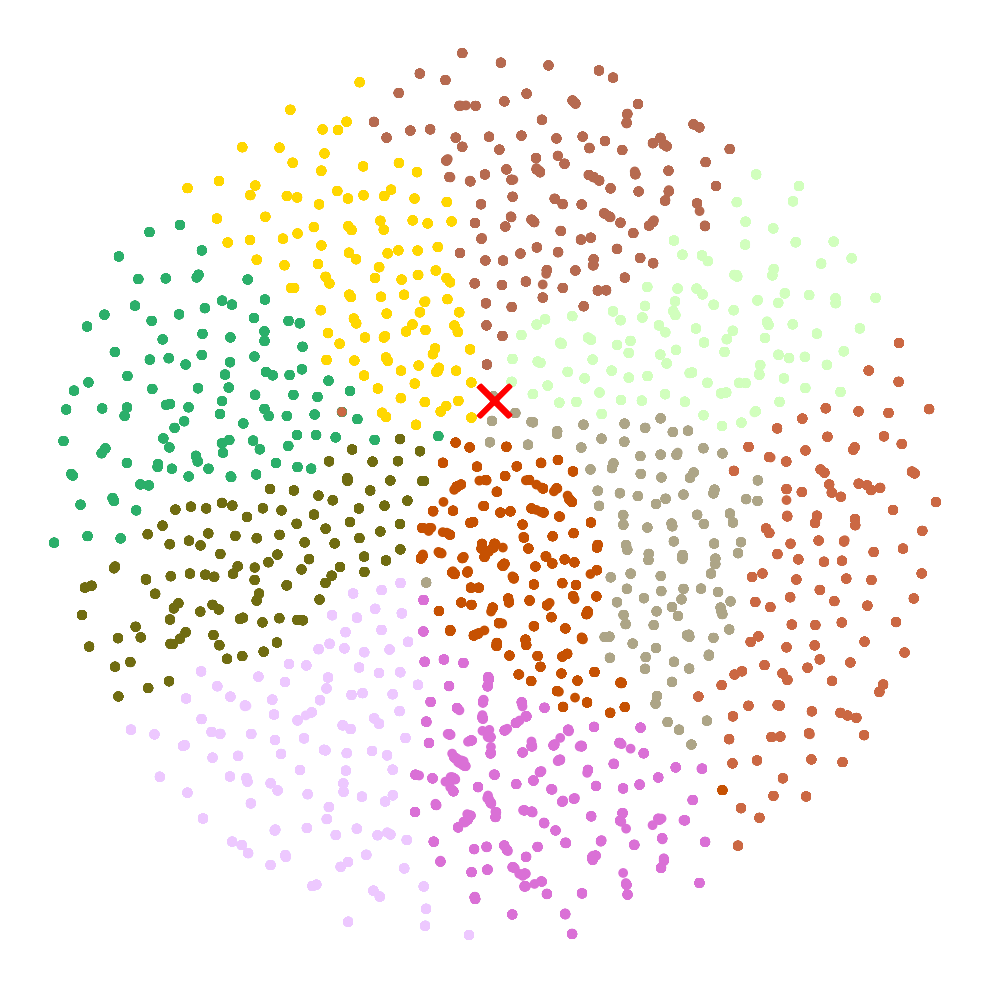

In [12]:
cluster_centers = autoencoder.get_cluster_centers().cpu().detach().numpy()
data, latent_data, labels = autoencoder.get_latent_data()
visualization.plot_tsne(latent_data, labels, clustering, cluster_centers, autoencoder.data_dir_path)